                     PJME_MW
Datetime                    
2002-01-01 01:00:00  30393.0
2002-01-01 02:00:00  29265.0
2002-01-01 03:00:00  28357.0
2002-01-01 04:00:00  27899.0
2002-01-01 05:00:00  28057.0
...                      ...
2018-08-02 20:00:00  44057.0
2018-08-02 21:00:00  43256.0
2018-08-02 22:00:00  41552.0
2018-08-02 23:00:00  38500.0
2018-08-03 00:00:00  35486.0

[145392 rows x 1 columns]


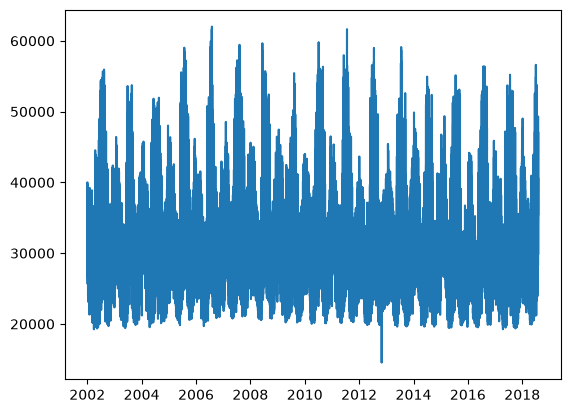

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime

#1.Descargar datos

df = pd.read_csv("D:/Projectes/Kaggle/Energy Consumption/PJME_hourly.csv", parse_dates=["Datetime"], index_col=["Datetime"])    #Pasamos la col "Datetime" de Str a Date, y la usamos de índice para la tabla
df = df.sort_index()        #Por si hay algun valor fuera de lugar
df = df[~df.index.duplicated(keep="first")]   # quita los 4 duplicados
df = df.asfreq("h").interpolate()             # rellena las 30 horas que faltan

print(df)

plt.figure()
plt.plot(df["PJME_MW"])
plt.show()


In [3]:
#2. Exploración de los datos

print(df.isna().sum())                                      #Si no hay ningún NaN no hace falta interpolar la serie
df.index.to_series().diff().value_counts().head()           #Para mirar cada cuanto tenemos valores en nuestra serie y detectar si faltan datos o hay irregularidades

PJME_MW    0
dtype: int64


Datetime
0 days 01:00:00    145391
Name: count, dtype: int64

In [4]:
#3. Feature engineering

from pandas.tseries.holiday import USFederalHolidayCalendar

HORIZONTE = 24

calendar = USFederalHolidayCalendar()
holidays = calendar.holidays(start=df.index.min(), end=df.index.max())      #Contiene las fechas y horas con este formato: yyyy/mm/dd 00:00:00

#Qualitative features
df["Holiday"] = df.index.normalize().isin(holidays)                         #Normalizamos para tener todas las horas a 00:00:00
df["Day_of_week"] = df.index.day_of_week
df["Weekend"] = df["Day_of_week"] > 4                                      

#Quantitative features
df["Hour"] = df["PJME_MW"].index.hour
df["Day"] = df["PJME_MW"].index.day
df["Month"] = df["PJME_MW"].index.month
df["Quarter"] = df["PJME_MW"].index.quarter

#Lags
for lag in (24, 24*2, 24*7):
    df[f"{lag}_Hours_Lag"] = df["PJME_MW"].shift(lag)

#Mean and Std
df["Rolling_mean_24h"] = df["PJME_MW"].shift(HORIZONTE).rolling(24).mean()
df["Rolling_std_24h"] = df["PJME_MW"].shift(HORIZONTE).rolling(24).std()

df = df.dropna()

print(df.head(20))



                     PJME_MW  Holiday  Day_of_week  Weekend  Hour  Day  Month  \
Datetime                                                                        
2002-01-08 01:00:00  29445.0    False            1    False     1    8      1   
2002-01-08 02:00:00  28670.0    False            1    False     2    8      1   
2002-01-08 03:00:00  28375.0    False            1    False     3    8      1   
2002-01-08 04:00:00  28542.0    False            1    False     4    8      1   
2002-01-08 05:00:00  29261.0    False            1    False     5    8      1   
2002-01-08 06:00:00  31348.0    False            1    False     6    8      1   
2002-01-08 07:00:00  35335.0    False            1    False     7    8      1   
2002-01-08 08:00:00  37841.0    False            1    False     8    8      1   
2002-01-08 09:00:00  37417.0    False            1    False     9    8      1   
2002-01-08 10:00:00  36824.0    False            1    False    10    8      1   
2002-01-08 11:00:00  36504.0

In [5]:
#4. Train / Test split

Division_date = "2017-01-01"
train = df.loc[df.index <= Division_date]
test = df.loc[df.index > Division_date]
y_train, y_test = train["PJME_MW"], test["PJME_MW"]
print(train.info())

#6. Baseline prediction

baseline_pred =  test["168_Hours_Lag"]             #Predecimos el mismo consumo que hace una semana


<class 'pandas.DataFrame'>
DatetimeIndex: 131328 entries, 2002-01-08 01:00:00 to 2017-01-01 00:00:00
Freq: h
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   PJME_MW           131328 non-null  float64
 1   Holiday           131328 non-null  bool   
 2   Day_of_week       131328 non-null  int32  
 3   Weekend           131328 non-null  bool   
 4   Hour              131328 non-null  int32  
 5   Day               131328 non-null  int32  
 6   Month             131328 non-null  int32  
 7   Quarter           131328 non-null  int32  
 8   24_Hours_Lag      131328 non-null  float64
 9   48_Hours_Lag      131328 non-null  float64
 10  168_Hours_Lag     131328 non-null  float64
 11  Rolling_mean_24h  131328 non-null  float64
 12  Rolling_std_24h   131328 non-null  float64
dtypes: bool(2), float64(6), int32(5)
memory usage: 9.8 MB
None


In [6]:
#5 Prophet

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

def to_prophet(d):
    out = d[["PJME_MW", "24_Hours_Lag", "168_Hours_Lag"]].reset_index()
    out.columns = ["ds", "y", "lag_24", "lag_168"]
    return out

train_prophet, test_prophet = to_prophet(train), to_prophet(test)

modelo = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,
    seasonality_mode="additive"
)

modelo.add_regressor("lag_24")
modelo.add_regressor("lag_168")
modelo.fit(train_prophet)


forecast = modelo.predict(test_prophet[["ds", "lag_24", "lag_168"]])
pred_prophet = pd.Series(forecast["yhat"].to_numpy(), index=test.index)

Importing plotly failed. Interactive plots will not work.
d:\Projectes\Kaggle\titanic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
18:53:34 - cmdstanpy - INFO - Chain [1] start processing
18:54:12 - cmdstanpy - INFO - Chain [1] done processing


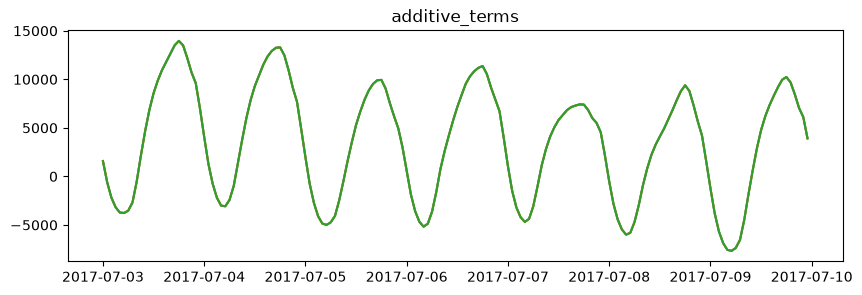

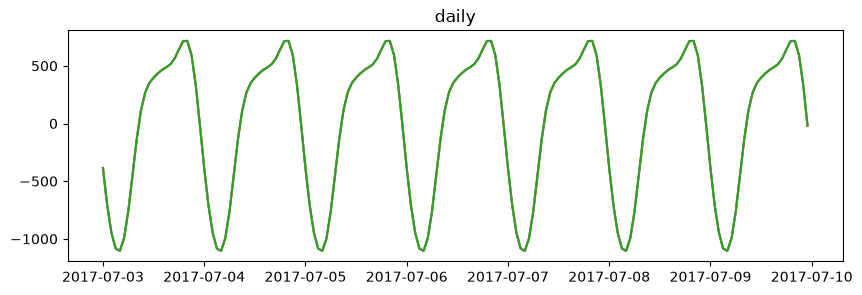

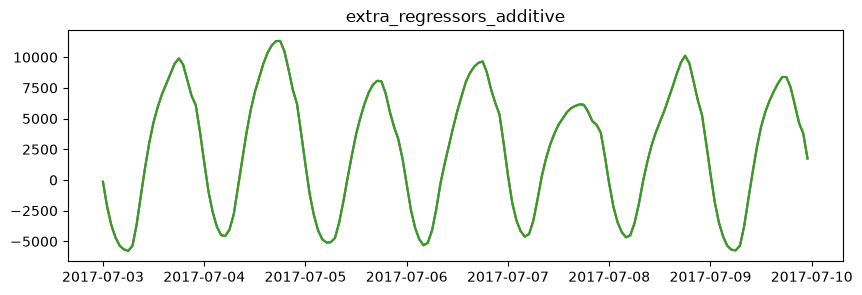

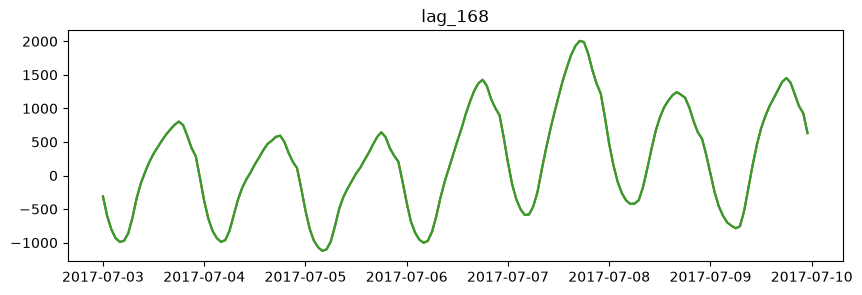

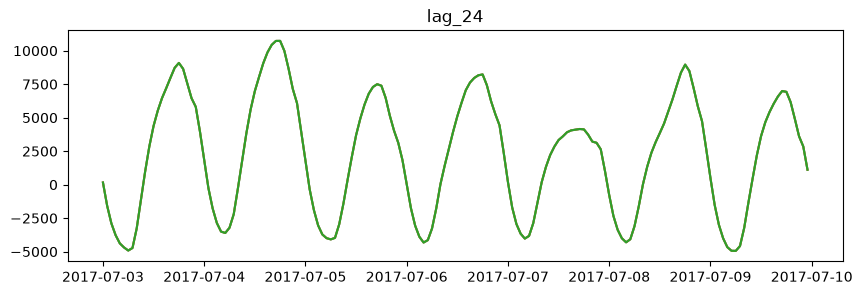

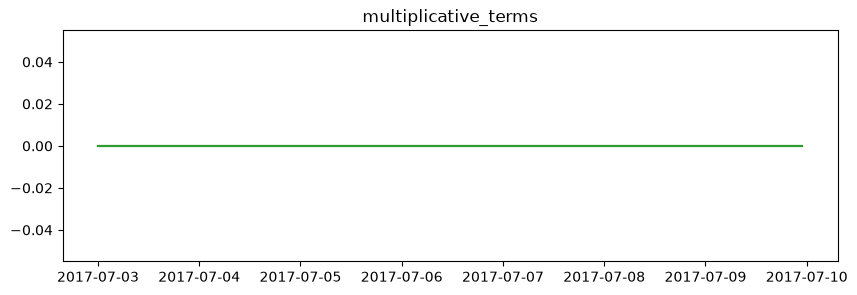

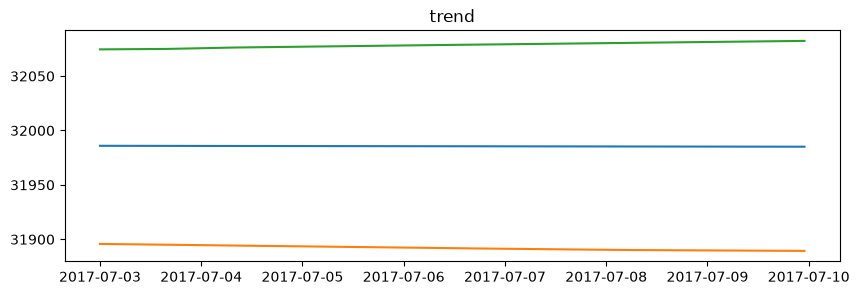

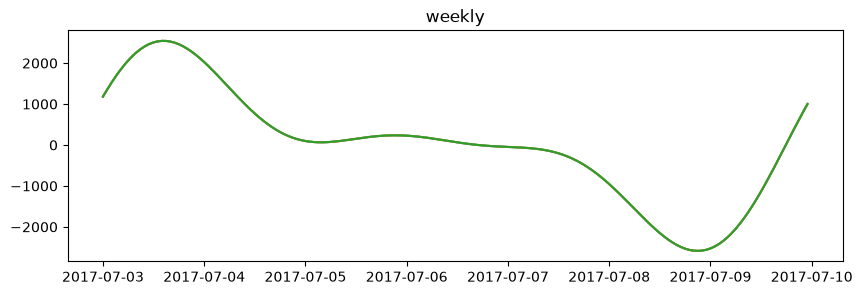

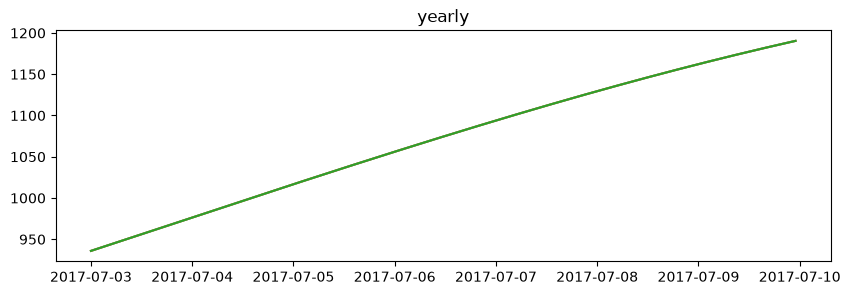

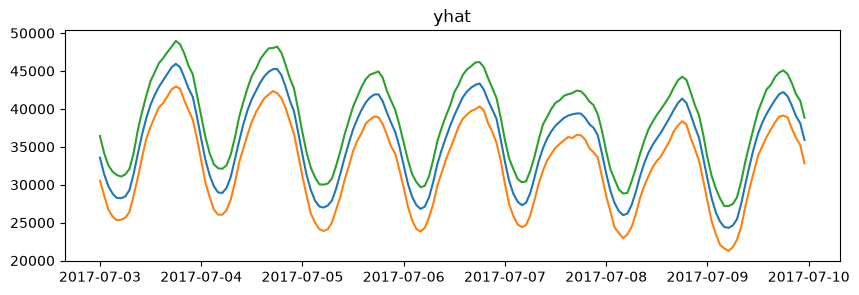

In [7]:

semana = forecast.set_index("ds").loc["2017-07-03":"2017-07-09"]

for i, col in enumerate(sorted(semana.columns)):
    if i % 3 == 0:
        plt.figure(figsize=(10, 3))
        plt.title(col)
    plt.plot(semana[col], label=col)

plt.show()


In [8]:
# MAE Prophet

mae_prophet = mean_absolute_error(y_test, pred_prophet)

# MAE Baseline

mae_baseline = mean_absolute_error(y_test, baseline_pred)

print(f"MAE Prophet: {mae_prophet:.2f} MW")
print(f"MAE Baseline prediction: {mae_baseline:.2f} MW")

MAE Prophet: 1974.84 MW
MAE Baseline prediction: 3511.39 MW


In [9]:
#6 LightGBM

import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit

print(train.columns)
features = train.columns.drop("PJME_MW")

X_train, X_test = train[features], test[features]

modelo_lgb = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, importance_type="gain")
modelo_lgb.fit(X_train, y_train)


Index(['PJME_MW', 'Holiday', 'Day_of_week', 'Weekend', 'Hour', 'Day', 'Month',
       'Quarter', '24_Hours_Lag', '48_Hours_Lag', '168_Hours_Lag',
       'Rolling_mean_24h', 'Rolling_std_24h'],
      dtype='str')
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001022 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1360
[LightGBM] [Info] Number of data points in the train set: 131328, number of used features: 12
[LightGBM] [Info] Start training from score 32185.146477


,learning_rate,0.05
,n_estimators,500
,importance_type,'gain'
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [10]:

#Cross validation temporal

from sklearn.metrics import mean_absolute_error

time_series_cross_val = TimeSeriesSplit(n_splits=5)
scores = []

for fold, (train_idx, val_idx) in enumerate(time_series_cross_val.split(X_train)):          #split te da los valores de los índices deentrenamiento y evaluación de cada fold
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    modelo_fold = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1)
    modelo_fold.fit(X_tr, y_tr)

    pred_val = modelo_fold.predict(X_val)
    mae = mean_absolute_error(y_val, pred_val)
    scores.append(mae)
    print(f"Fold {fold+1}: MAE = {mae:.2f} MW")

print(f"MAE promedio = {np.mean(scores):.2f} +- {np.std(scores):.2f} MW")


Fold 1: MAE = 1566.40 MW
Fold 2: MAE = 1603.03 MW
Fold 3: MAE = 1545.45 MW
Fold 4: MAE = 1647.60 MW
Fold 5: MAE = 1638.59 MW
MAE promedio = 1600.21 +- 39.67 MW


MAE Modelo final: 1871.19 MW


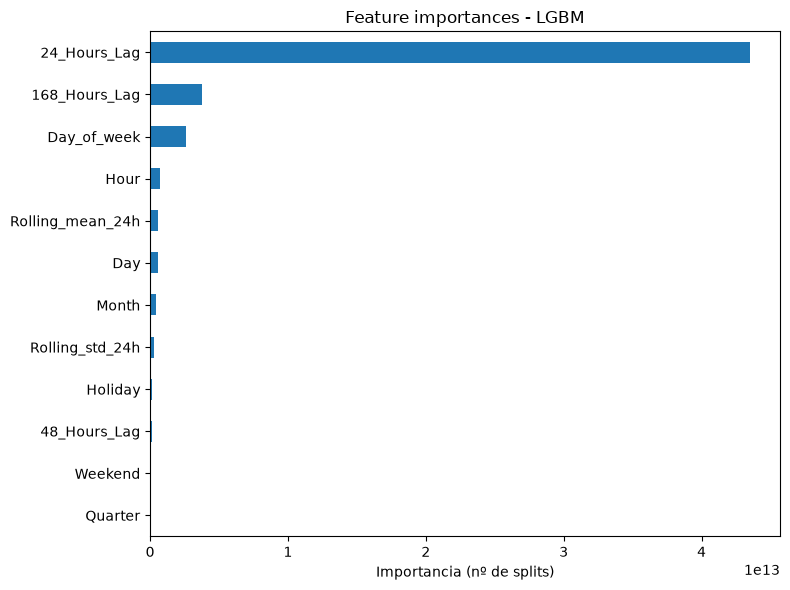

In [11]:
#Evaluación final del modelo

pred_lgb = modelo_lgb.predict(X_test)
print(f"MAE Modelo final: {mean_absolute_error(y_test, pred_lgb):.2f} MW")

importancias_lgbm = pd.Series(
    modelo_lgb.feature_importances_,
    index=X_train.columns          # mismo orden con el que se entrenó el modelo
).sort_values(ascending=True)      # de menor a mayor: en barh el último queda arriba

plt.figure(figsize=(8, 6))
importancias_lgbm.plot(kind="barh")
plt.title("Feature importances - LGBM")
plt.xlabel("Importancia (nº de splits)")
plt.tight_layout()
plt.show()

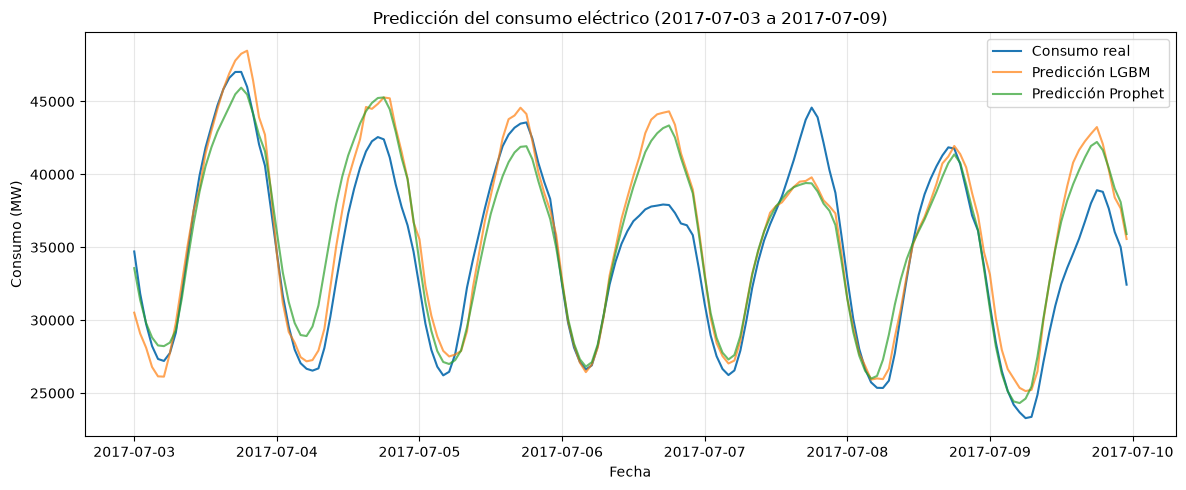

In [12]:
#Comparación de modelos / estrategias

pred_lgb_s = pd.Series(pred_lgb, index=y_test.index)

ini, fin = "2017-07-03", "2017-07-09"      #Miramos solo una semana para visualizarlo mejor

plt.figure(figsize=(12, 5))
plt.plot(y_test.loc[ini:fin], label="Consumo real")
plt.plot(pred_lgb_s.loc[ini:fin], label="Predicción LGBM", alpha=0.7)
plt.plot(pred_prophet.loc[ini:fin], label="Predicción Prophet", alpha=0.7)

plt.title(f"Predicción del consumo eléctrico ({ini} a {fin})")
plt.xlabel("Fecha")
plt.ylabel("Consumo (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()